# Logistic Regression:

---

## Importing Libraries:

In [1]:
import time

import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, cross_validate, StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_curve, roc_auc_score, make_scorer

import warnings
warnings.filterwarnings('ignore')

## Importing Dataset:

In [2]:
data = pd.read_csv("email_spam_features.csv")

## Building Base Model:

In [3]:
X = data.drop(columns=['Category'])
y = data['Category']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=69)

In [4]:
label = LabelEncoder()

y_train = label.fit_transform(y_train)
y_test = label.transform(y_test)

In [5]:
lr = LogisticRegression(class_weight='balanced')

start_time = time.time()
lr.fit(X_train, y_train)
end_time = time.time() - start_time

print('Model Trained Sucessfully!')
print(f'Time Taken For Training: {end_time:.2f}s')

Model Trained Sucessfully!
Time Taken For Training: 0.24s


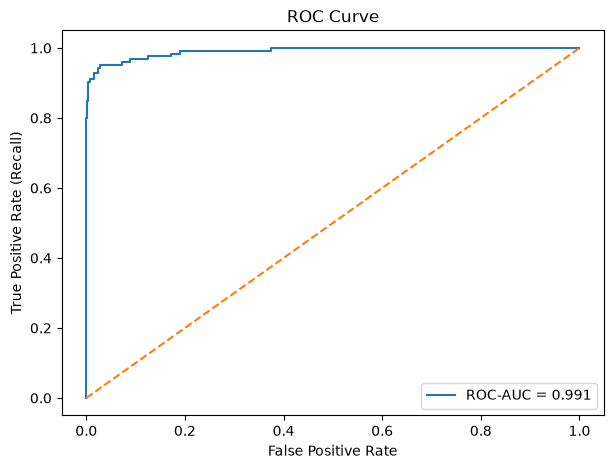

In [6]:
y_prob = lr.predict_proba(X_test)[:,1]

fpr, tpr, threshold = roc_curve(y_test, y_prob)

auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f'ROC-AUC = {auc:.3f}')
plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curve')
plt.legend()
plt.show()

In [7]:
y_pred = lr.predict(X_test)

print(f"Accuracy: {(accuracy_score(y_test, y_pred) * 100):.2f}%")

print(f"\nPrecision: {(precision_score(y_test, y_pred)*100):.2f}%")

print(f"\nRecall: {(recall_score(y_test, y_pred)*100):.2f}%")

print(f"\nF1 Score: {(f1_score(y_test, y_pred)*100):.2f}%")

Accuracy: 97.48%

Precision: 87.22%

Recall: 92.80%

F1 Score: 89.92%


In [8]:
matrix = confusion_matrix(y_test, y_pred)
matrix_df = pd.DataFrame(matrix, index=['Actual ham', 'Actual spam'], columns=['Predicted ham', 'Predicted spam'])
matrix_df

,Predicted ham,Predicted spam
Actual ham,890,17
Actual spam,9,116


## Hyper-Parameter Tuning:

In [9]:
params = {'C' : [0.01, 0.1, 1, 10, 100],
         'class_weight' : ['balanced', None]}

grid = GridSearchCV(
    estimator=LogisticRegression(),
    param_grid=params,
    scoring='precision',
    cv=5,
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best Parameters:", grid.best_params_)

Best Parameters: {'C': 10, 'class_weight': None}


In [10]:
params = {'C' : [0.01, 0.1, 1, 10, 100],
         'class_weight' : ['balanced', None]}

grid = GridSearchCV(
    estimator=LogisticRegression(),
    param_grid=params,
    scoring='f1',
    cv=5,
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best Parameters:", grid.best_params_)

Best Parameters: {'C': 10, 'class_weight': None}


In [11]:
Lr = LogisticRegression(C=10, class_weight=None)

start_time = time.time()
Lr.fit(X_train, y_train)
end_time = time.time() - start_time

print('Model Trained Sucessfully!')
print(f'Time Taken For Training: {end_time:.2f}s')

Model Trained Sucessfully!
Time Taken For Training: 0.18s


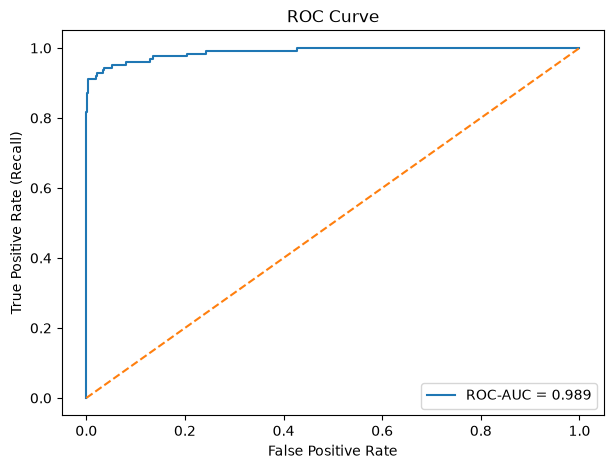

In [12]:
y_prob = Lr.predict_proba(X_test)[:,1]

fpr, tpr, threshold = roc_curve(y_test, y_prob)

auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f'ROC-AUC = {auc:.3f}')
plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curve')
plt.legend()
plt.show()

In [13]:
y_pred = Lr.predict(X_test)

print(f"Accuracy: {(accuracy_score(y_test, y_pred) * 100):.2f}%")

print(f"\nPrecision: {(precision_score(y_test, y_pred)*100):.2f}%")

print(f"\nRecall: {(recall_score(y_test, y_pred)*100):.2f}%")

print(f"\nF1 Score: {(f1_score(y_test, y_pred)*100):.2f}%")

Accuracy: 98.26%

Precision: 98.20%

Recall: 87.20%

F1 Score: 92.37%


In [14]:
matrix = confusion_matrix(y_test, y_pred)
matrix_df = pd.DataFrame(matrix, index=['Actual ham', 'Actual spam'], columns=['Predicted ham', 'Predicted spam'])
matrix_df

,Predicted ham,Predicted spam
Actual ham,905,2
Actual spam,16,109


## Cross-Validation:

In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=69)

scoring = {
    'accuracy' : 'accuracy',
    'precision' : make_scorer(precision_score, pos_label='spam'),
    'recall' : make_scorer(recall_score, pos_label='spam'),
    'f1' : make_scorer(f1_score, pos_label='spam')
}

result = cross_validate(
    estimator=LogisticRegression(C=10),
    X=X,
    y=y,
    scoring=scoring,
    cv=cv,
    n_jobs=-1
)

metrics = ['accuracy', 'precision', 'recall', 'f1']

for i in metrics:
    score = result[f'test_{i}']
    print(f"{i.capitalize()}: {np.mean(score)*100:.2f}%\n")

Accuracy: 98.57%

Precision: 97.20%

Recall: 91.11%

F1: 94.04%



## Experimentation: Scaling

In [16]:
preprocessing = ColumnTransformer(transformers=[
    ('scale', StandardScaler(), X.columns)
], remainder='passthrough')

model_pipeline = Pipeline(steps=[
     ('preprocessing', preprocessing),
     ('model', LogisticRegression(C=10))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=69)

scoring = {
    'accuracy' : 'accuracy',
    'precision' : make_scorer(precision_score, pos_label='spam'),
    'recall' : make_scorer(recall_score, pos_label='spam'),
    'f1' : make_scorer(f1_score, pos_label='spam')
}

result = cross_validate(
    estimator=model_pipeline,
    X=X,
    y=y,
    scoring=scoring,
    cv=cv,
    n_jobs=-1
)

metrics = ['accuracy', 'precision', 'recall', 'f1']

for i in metrics:
    score = result[f'test_{i}']
    print(f"{i.capitalize()}: {np.mean(score)*100:.2f}%\n")

Accuracy: 98.68%

Precision: 97.84%

Recall: 91.42%

F1: 94.51%

